In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


# Load the Boston dataset

In [56]:
from sklearn.datasets import fetch_california_housing

In [57]:
california_df = fetch_california_housing()
type(california_df)

sklearn.utils._bunch.Bunch

In [58]:
california_df.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [59]:
california_df.data.shape

(20640, 8)

In [60]:
california_df.target.shape

(20640,)

In [61]:
california_df.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [62]:
df = pd.DataFrame(
    california_df.data,
    columns=california_df.feature_names
)

In [63]:
df['Price'] = california_df.target

In [64]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [65]:
df.sample(5)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
16711,3.5682,10.0,6.100875,1.023907,4660.0,2.717201,35.03,-120.50,2.773
5042,1.7067,49.0,4.304878,1.015244,901.0,2.746951,33.98,-118.32,1.186
12108,3.4896,28.0,5.213415,1.053354,1502.0,2.289634,33.97,-117.31,1.403
16663,3.0833,44.0,5.116705,0.940503,1036.0,2.370709,35.29,-120.67,2.193
16923,3.3800,28.0,4.064234,1.074453,1534.0,2.239416,37.58,-122.33,2.854


In [66]:
df.shape

(20640, 9)

In [67]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'Price'],
      dtype='object')

In [68]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [69]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [70]:
#Check missing values

df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Price         0
dtype: int64

In [71]:
#Check duplicate records

df.duplicated().sum()

np.int64(0)

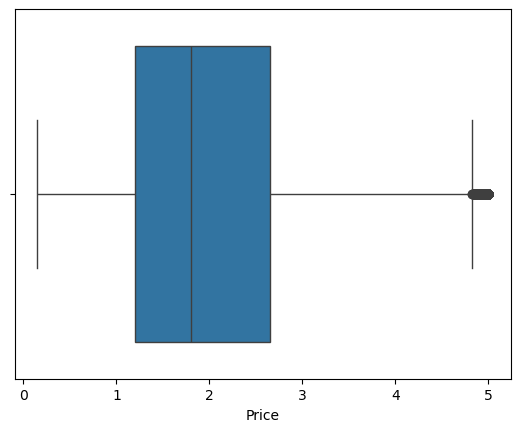

In [72]:
#Check outliers

sns.boxplot(x=df['Price'])
plt.show()

In [73]:
df['Price'].max()

5.00001

# EDA

Distribution of House Prices

**Objective:** Analyze the distribution of the target variable (`Price`) to understand how house prices are distributed across the dataset.

We will use a histogram with a KDE curve to visualize the frequency distribution of house prices.

This analysis will help us:
- Understand the most frequently occurring price ranges.
- Identify whether the distribution is symmetric or skewed.
- Observe the spread of house prices.
- Identify any unusual patterns in the distribution.

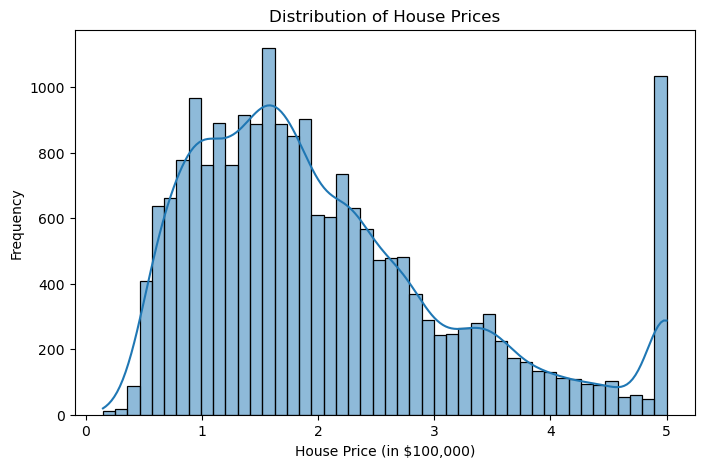

In [74]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Price', kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('House Price (in $100,000)')
plt.ylabel('Frequency')

plt.show()

### Observations – Distribution of House Prices

- Most house prices are concentrated between approximately 0.5 and 2.5.
- The distribution is positively skewed (right-skewed), indicating that relatively fewer observations have higher house prices.
- A noticeable spike is observed near 5.0.
- This spike occurs because the target variable is capped at approximately $500,000 in the original California Housing dataset.
- The distribution is not perfectly normal or symmetric.

## Bivariate Analysis

### Median Income vs House Price

**Objective:** Analyze the relationship between median household income (`MedInc`) and house prices (`Price`).

We will use a scatter plot to visualize how house prices vary with changes in median household income.

This analysis will help us:
- Identify the relationship between median income and house prices.
- Understand whether the relationship is positive or negative.
- Observe patterns and trends in the data.
- Determine whether median income could be an important predictor of house prices.

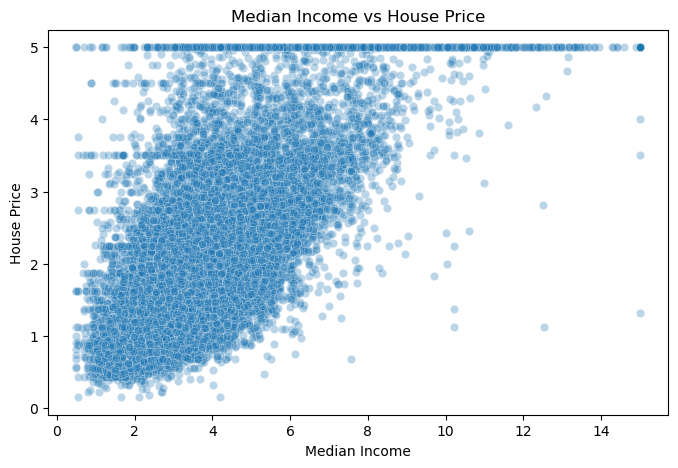

In [75]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='MedInc', y='Price', alpha=0.3)

plt.title('Median Income vs House Price')
plt.xlabel('Median Income')
plt.ylabel('House Price')

plt.show()

### Average Rooms vs House Price

**Objective:** Analyze the relationship between the average number of rooms per household (`AveRooms`) and house prices (`Price`).

A scatter plot will be used to visualize how house prices vary with the average number of rooms.

This analysis will help us identify patterns and understand whether the number of rooms could be a useful predictor of house prices.

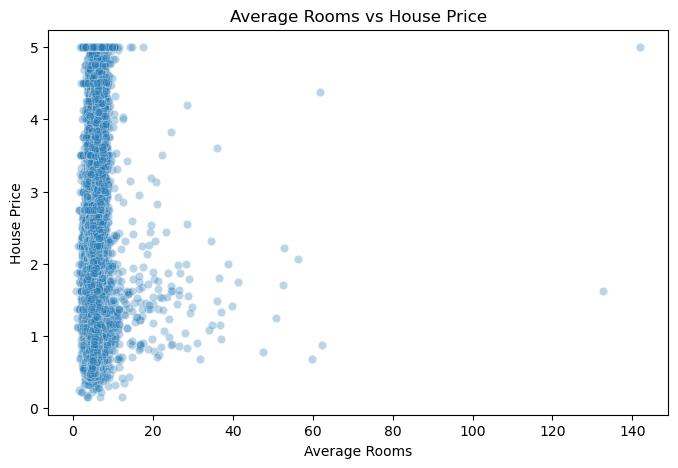

In [76]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='AveRooms', y='Price', alpha=0.3)

plt.title('Average Rooms vs House Price')
plt.xlabel('Average Rooms')
plt.ylabel('House Price')

plt.show()

### Observations – Average Rooms vs House Price

- Most observations are concentrated between 0 and 10 average rooms.
- The scatterplot does not show a strong linear relationship between average rooms and house prices.
- House prices vary considerably even for similar average room counts.
- A few observations have unusually high average room values.
- Average rooms alone may not be sufficient to explain variations in house prices.

### House Age vs House Price

**Objective:** Analyze the relationship between the median age of houses (`HouseAge`) and house prices (`Price`).

A scatter plot will be used to visualize how house prices vary with the age of houses.

This analysis will help us understand whether house age shows any noticeable relationship with house prices.

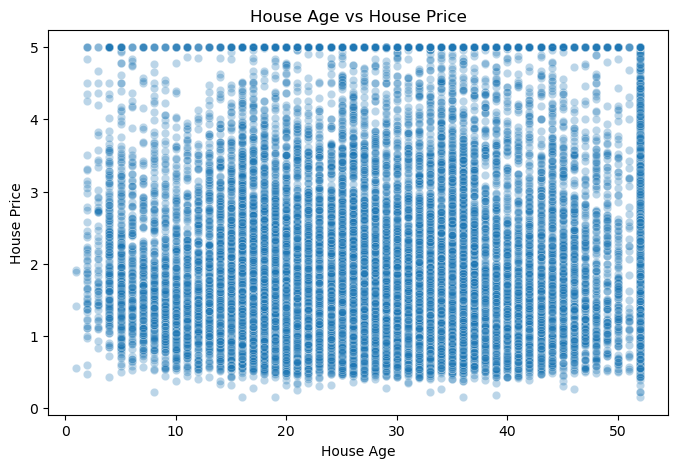

In [77]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='HouseAge', y='Price', alpha=0.3)

plt.title('House Age vs House Price')
plt.xlabel('House Age')
plt.ylabel('House Price')

plt.show()

### Observations – House Age vs House Price

- House ages range from approximately 1 to 52 years.
- The scatterplot does not indicate a strong linear relationship between house age and house prices.
- Significant variations in house prices can be observed for houses with similar ages.
- The target variable shows a concentration at 5.0 due to the upper price cap in the dataset.
- House age alone does not explain the variations in house prices.

## Correlation Analysis

**Objective:** Analyze the correlation between independent features and the target variable (`Price`).

A correlation heatmap will be used to visualize the strength and direction of linear relationships between numerical variables.

This analysis will help us:
- Identify features that have stronger linear relationships with house prices.
- Understand relationships between independent features.
- Identify potential multicollinearity among input features.

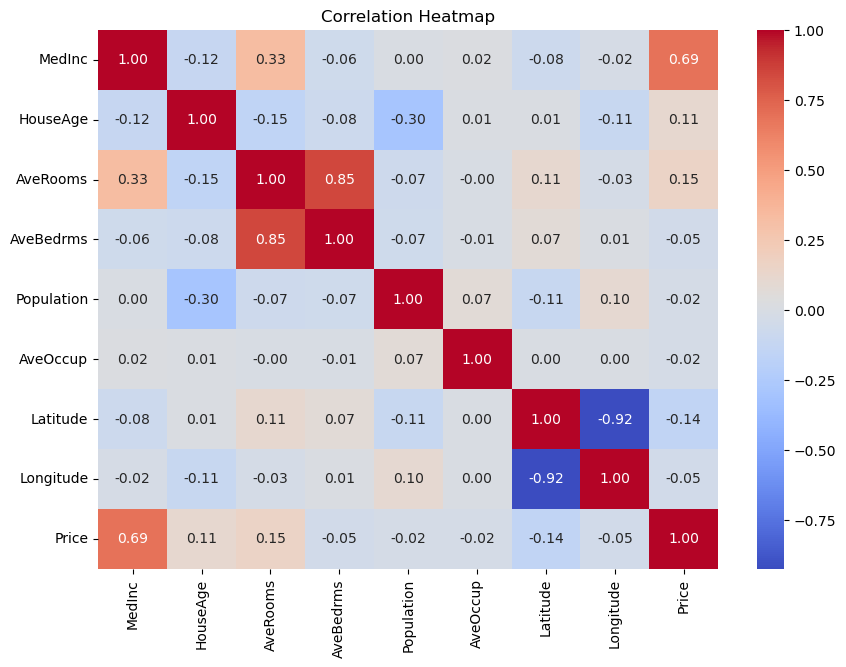

In [78]:
plt.figure(figsize=(10, 7))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

### Observations – Correlation Analysis

- MedInc has the strongest positive correlation with Price (0.69), indicating that median household income has a relatively strong positive linear relationship with house prices.
- HouseAge (0.11) and AveRooms (0.15) show weak positive correlations with Price.
- AveBedrms (-0.05), Population (-0.02), and AveOccup (-0.02) show very weak negative correlations with Price.
- Latitude (-0.14) and Longitude (-0.05) show weak negative correlations with Price.
- AveRooms and AveBedrms have a strong positive correlation (0.85).
- Latitude and Longitude have a strong negative correlation (-0.92).

**Conclusion:** MedInc appears to be the most strongly linearly associated feature with Price. However, other features may also contribute to prediction through nonlinear relationships and interactions.

## Data Preprocessing

### Separating Independent and Dependent Variables (X and y)

**Objective:** Separate the input features (X) from the target variable (y) before training the Machine Learning model.

- **Independent Variables (X):** These are the input features used by the model to make predictions.
- **Dependent Variable (y):** This is the target variable that the model aims to predict.

In our House Price Prediction project:
- X contains all eight independent features.
- y contains the `Price` column, which represents the median house value.

This separation allows the model to learn the relationship between input features and house prices.

In [79]:
X = df.drop('Price', axis=1)
y = df['Price']

In [80]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (20640, 8)
Shape of y: (20640,)


### Train-Test Split

**Objective:** Divide the dataset into training and testing subsets.

- Training data is used by the Machine Learning model to learn patterns.
- Testing data is used to evaluate the model's performance on unseen data.

We will use an 80:20 split:
- 80% for training.
- 20% for testing.

This helps us evaluate how well our model generalizes to unseen observations.

In [81]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [82]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)
y_train: (16512,)
y_test: (4128,)


### Feature Scaling

**Objective:** Bring numerical features to a comparable scale.

Our dataset contains features with different ranges. For example:

- MedInc ranges approximately from 0 to 15.
- HouseAge ranges from 1 to 52.
- Population can reach several thousand.

Features with very different scales can affect certain Machine Learning algorithms.

We will use `StandardScaler` to standardize the input features.

Standardization transforms the features so that they have approximately:

- Mean = 0
- Standard deviation = 1

The formula is:

z = (x - mean) / standard deviation

We will fit the scaler only on the training data to avoid data leakage. The same learned scaling values will then be applied to the testing data.

In [83]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [84]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (16512, 8)
X_test_scaled: (4128, 8)


## Model Training

### Linear Regression

**Objective:** Train a Linear Regression model to predict house prices using the available input features.

Linear Regression is a supervised Machine Learning algorithm used for predicting continuous numerical values.

It learns the relationship between the input features (X) and the target variable (y).

The model tries to find the best-fitting linear relationship between the features and house prices.

We will train the model using the scaled training data.

In [85]:
from sklearn.linear_model import LinearRegression

# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Understanding Model Training

The `fit()` method trains the model using the training dataset.

- `X_train_scaled`: Input features used for learning.
- `y_train`: Actual house prices.
- `model`: The trained Linear Regression model.

During training, the model learns coefficients and an intercept that minimize the sum of squared prediction errors.

In [86]:
print("Model Coefficients:", model.coef_)
print("Model Intercept:", model.intercept_)

Model Coefficients: [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]
Model Intercept: 2.071946937378881


## Model Prediction

**Objective:** Use the trained Linear Regression model to predict house prices for the testing dataset.

We use the `predict()` method to generate predictions using the unseen testing data.

These predictions will later be compared with the actual house prices to evaluate model performance.

In [87]:
y_pred = model.predict(X_test_scaled)

In [88]:
print("First 10 Predicted Prices:")
print(y_pred[:10])

First 10 Predicted Prices:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725 2.01175367
 2.64550005 2.16875532 2.74074644 3.91561473]


## Model Evaluation

**Objective:** Evaluate the performance of our Linear Regression model using different regression metrics.

We will use the following evaluation metrics:

1. **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted values.

2. **MSE (Mean Squared Error):** Measures the average squared difference between actual and predicted values.

3. **RMSE (Root Mean Squared Error):** Represents the square root of MSE and expresses prediction error in the original target units.

4. **R² Score (Coefficient of Determination):** Measures how much variation in the target variable is explained by the model.

These metrics help us understand how accurately our model predicts house prices.

In [89]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.5332001304956565
MSE: 0.555891598695244
RMSE: 0.7455813830127761
R2 Score: 0.5757877060324511


### Actual vs Predicted Price Visualization

We use a scatter plot to compare actual house prices with predicted house prices.

If predictions are accurate, the points should lie close to the diagonal line.

This visualization helps identify how closely the model's predictions follow the actual values.

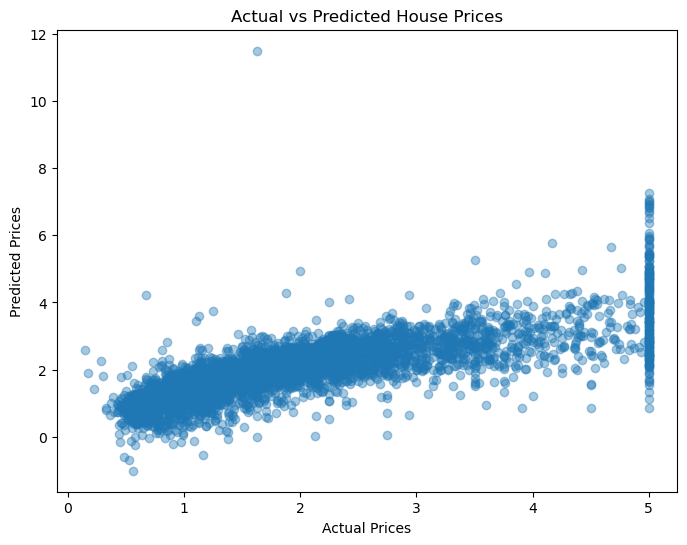

In [90]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()


### Actual vs Predicted Prices with Reference Line

The diagonal reference line represents perfect predictions, where actual prices equal predicted prices.

Points closer to this line indicate more accurate predictions.

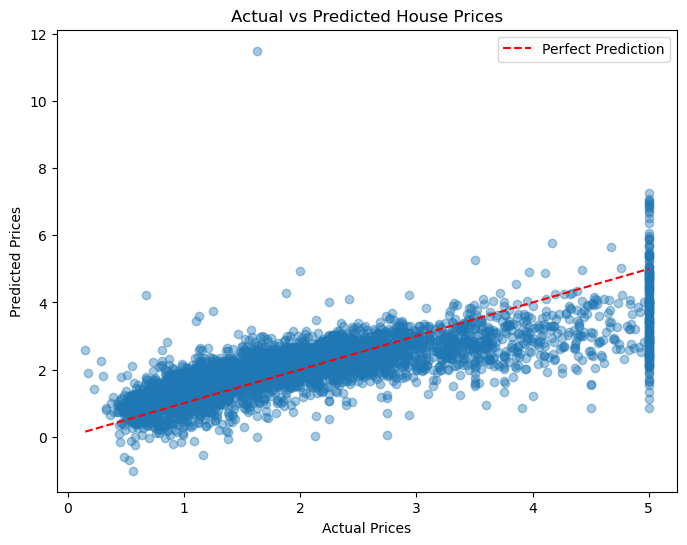

In [91]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted House Prices")
plt.legend()

plt.show()

**Observations:**

- The model captures a positive relationship between actual and predicted house prices.
- Several predictions deviate from actual values.
- The model struggles with some high-priced houses.
- The R² score of 0.5758 indicates that the model explains approximately 57.58% of the variation in the test dataset.

Overall, Linear Regression provides a baseline model, but its predictive performance can potentially be improved.

## Decision Tree Regression

**Objective:** Train a Decision Tree Regression model to predict house prices.

A Decision Tree is a supervised Machine Learning algorithm that learns patterns by splitting the dataset into smaller subsets based on feature values.

Unlike Linear Regression, a Decision Tree can capture nonlinear relationships between input features and the target variable.

For this model, we will use the original training data (`X_train`) instead of scaled data because Decision Trees do not require feature scaling.

In [92]:
from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree model
dt_model = DecisionTreeRegressor(random_state=42)

In [93]:
dt_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [94]:
y_pred_dt = dt_model.predict(X_test)

In [95]:
print("First 10 Predicted Prices:")
print(y_pred_dt[:10])

First 10 Predicted Prices:
[0.414   1.203   5.00001 2.17    2.257   1.787   2.217   1.74    2.772
 5.00001]


In [96]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae_dt = mean_absolute_error(y_test, y_pred_dt)

mse_dt = mean_squared_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(mse_dt)

r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree MAE:", mae_dt)
print("Decision Tree MSE:", mse_dt)
print("Decision Tree RMSE:", rmse_dt)
print("Decision Tree R2 Score:", r2_dt)

Decision Tree MAE: 0.45467918846899225
Decision Tree MSE: 0.495235205629094
Decision Tree RMSE: 0.7037294974840077
Decision Tree R2 Score: 0.622075845135081


### Comparison: Linear Regression vs Decision Tree

We compared both models using MAE, MSE, RMSE and R² Score.

**Observations:**

- Decision Tree achieved a lower MAE, MSE and RMSE than Linear Regression.
- Decision Tree achieved a higher R² Score of 0.6221 compared to 0.5758 for Linear Regression.
- Decision Tree performed better on the test dataset across all four evaluation metrics.

Therefore, Decision Tree is currently the better-performing model among the two.

## Random Forest Regression

**Objective:** Train a Random Forest Regression model to predict house prices.

Random Forest is a supervised Machine Learning algorithm based on ensemble learning.

It creates multiple Decision Trees and combines their predictions to produce the final output.

For regression problems, the final prediction is generally the average of the predictions from all the trees.

Unlike a single Decision Tree, Random Forest can reduce prediction variance and help improve generalization.

Feature scaling is not required for Random Forest.

In [97]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(random_state=42)

In [98]:
rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [99]:
y_pred_rf = rf_model.predict(X_test)

In [100]:
print("First 10 Predicted Prices:")
print(y_pred_rf[:10])


First 10 Predicted Prices:
[0.5095    0.74161   4.9232571 2.52961   2.27369   1.64692   2.37605
 1.66932   2.7729706 4.9134589]


In [101]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest MAE:", mae_rf)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)
print("Random Forest R2 Score:", r2_rf)

Random Forest MAE: 0.32754256845930246
Random Forest MSE: 0.2553684927247781
Random Forest RMSE: 0.5053399773665033
Random Forest R2 Score: 0.8051230593157366


### Model Performance Comparison

We compare the performance of all three regression algorithms using MAE, MSE, RMSE and R² Score.

This comparison helps us identify the best-performing model based on the testing dataset.

In [102]:
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'MAE': [mae, mae_dt, mae_rf],
    'MSE': [mse, mse_dt, mse_rf],
    'RMSE': [rmse, rmse_dt, rmse_rf],
    'R2 Score': [r2, r2_dt, r2_rf]
})

model_comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,0.533200,0.555892,0.745581,0.575788
1,Decision Tree,0.454679,0.495235,0.703729,0.622076
2,Random Forest,0.327543,0.255368,0.505340,0.805123


### Checking Overfitting

Overfitting occurs when a Machine Learning model learns the training data too closely, including noise and specific patterns that may not generalize to unseen data.

We compare the R² scores on training and testing datasets to understand how well the model generalizes.

In [103]:
y_train_pred_rf = rf_model.predict(X_train)

train_r2_rf = r2_score(y_train, y_train_pred_rf)

test_r2_rf = r2_score(y_test, y_pred_rf)

print("Training R2 Score:", train_r2_rf)
print("Testing R2 Score:", test_r2_rf)


Training R2 Score: 0.9735726320302575
Testing R2 Score: 0.8051230593157366


### Random Forest Hyperparameter Tuning

**Objective:** Reduce overfitting by controlling the complexity of individual decision trees.

We will limit the maximum depth of each tree using the `max_depth` parameter.

We will train a new Random Forest model and compare its training and testing performance with the previous model.

In [104]:
rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42
)

rf_tuned.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [105]:
y_train_pred_tuned = rf_tuned.predict(X_train)
y_test_pred_tuned = rf_tuned.predict(X_test)

train_r2_tuned = r2_score(y_train, y_train_pred_tuned)
test_r2_tuned = r2_score(y_test, y_test_pred_tuned)

print("Tuned Training R2:", train_r2_tuned)
print("Tuned Testing R2:", test_r2_tuned)

Tuned Training R2: 0.9567164152114612
Tuned Testing R2: 0.800365851772264


### Final Model Performance Comparison

We compare Linear Regression, Decision Tree, Original Random Forest
and Tuned Random Forest using their testing performance.

The objective is to identify the model that performs best on unseen data.

In [106]:
final_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'MAE': [
        mae, mae_dt, mae_rf,
        mean_absolute_error(y_test, y_test_pred_tuned)
    ],
    'RMSE': [
        rmse, rmse_dt, rmse_rf,
        np.sqrt(mean_squared_error(y_test, y_test_pred_tuned))
    ],
    'R2 Score': [
        r2, r2_dt, r2_rf, test_r2_tuned
    ]
})

final_comparison.sort_values(by='R2 Score', ascending=False)

,Model,MAE,RMSE,R2 Score
2,Random Forest,0.327543,0.505340,0.805123
3,Tuned Random Forest,0.333221,0.511471,0.800366
1,Decision Tree,0.454679,0.703729,0.622076
0,Linear Regression,0.533200,0.745581,0.575788


## Saving the Best Model

The Random Forest Regressor achieved the best performance among the evaluated models.

We will save this trained model using Joblib so that it can be reused later without training it again.

In [107]:
import joblib

joblib.dump(rf_model, 'house_price_model.pkl')

['house_price_model.pkl']

In [108]:
loaded_model = joblib.load('house_price_model.pkl')

In [109]:
print(loaded_model)

RandomForestRegressor(random_state=42)


In [110]:
loaded_model.predict(X_test.iloc[:5])

array([0.5095   , 0.74161  , 4.9232571, 2.52961  , 2.27369  ])

In [111]:
import joblib

joblib.dump(rf_model, 'house_price_model.pkl', compress=3)

['house_price_model.pkl']

In [112]:
import os

size_mb = os.path.getsize('house_price_model.pkl') / (1024 * 1024)

print(f"Model size: {size_mb:.2f} MB")

Model size: 31.19 MB
